# BlindCore Homomorphic Compute Demo: Zero-Plaintext Blind OLAP & Threshold Decryption

**Target Markets:** Healthcare / Hospitals (HIPAA), Financial Services / Banks, Defense & Intelligence  
**Workflow:** Declare mixed relational + IND-CPA lattice-encrypted columns -> Ingest sealed hospital cohort records -> Verify **zero plaintext** stored in SQL -> Evaluate live **Blind Homomorphic OLAP** (`SUM`, `ADD`, `SUB`, `WEIGHTED_SUM`, `Depth-0` signed `MUL` & `DIV` with `0` bootstrapping, and `Depth-2` `RANGE_GATE`) with `t-of-n` threshold decryption (`2-of-3` and `3-of-5`) and independent `NSAU0001` cryptographic receipt verification over TLS 1.3 on AlmaLinux 10.3 ARM64 (SELinux Enforcing).

### Why CISOs, Hospitals & Investors Care
- **Zero plaintext at rest or in compute:** Sensitive columns are stored strictly as opaque IND-CPA lattice ciphertext hex frames (`plaintext_stored: false`). Dumping the database yields zero patient financial or clinical values.
- **Zero-key blind compute:** Omitting `threshold_decrypt` executes homomorphic aggregates blindly on ciphertexts and returns only an encrypted result frame (`ct_result_hex`) -- never plaintext.
- **Exact `0`-error homomorphic math at microsecond-to-millisecond ARM64 speed:** Supports additive linear risk scoring (`WEIGHTED_SUM`), `Depth-0` exact signed `MUL` / `DIV` (`0` bootstrapping), and `Depth-2` `RANGE_GATE` anomaly checks.
- **Tamper-evident `NSAU0001` receipts + fail-closed guards:** Every schema, ingest, and query operation emits a verifiable `SHA-256` `NSAU0001` receipt, and invalid cryptographic probes fail closed with HTTP `422`.
- **Blind Encrypted `sklearn` Training & Inference (Section 6):** Computes exact homomorphic sufficient-statistic Gram matrices `(X^T X, X^T y)` over encrypted clinical rows to train `sklearn.linear_model.Ridge` with `< 1e-10` coefficient parity, followed by exact `0`-error encrypted `WEIGHTED_SUM` inference on held-out patients.

In [1]:
import hashlib
import hmac
import json
import math
import os
import struct
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "python" / "blindcore_sdk.py").is_file():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "python" / "blindcore_sdk.py").is_file(), (
    "Run Jupyter from blindcore-sdk/ or blindcore-sdk/notebooks/"
)
if str(REPO_ROOT / "python") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "python"))

from blindcore_sdk import BlindCoreClient

BLINDCORE_URL = os.environ["BLINDCORE_URL"].strip()
BLINDCORE_TOKEN = os.environ["BLINDCORE_TOKEN"].strip()
assert BLINDCORE_URL and BLINDCORE_TOKEN, "Set BLINDCORE_URL and BLINDCORE_TOKEN env vars"

client = BlindCoreClient(BLINDCORE_URL, BLINDCORE_TOKEN, timeout=30.0)


def verify_nsau0001_table_receipt(table: str, col_count: int, resp: dict) -> tuple[bool, str]:
    assert resp.get("receipt_magic") == "NSAU0001", f"Unexpected receipt magic: {resp.get('receipt_magic')}"
    srv_hex = str(resp.get("receipt_hex", ""))
    preimage = b"NSAU0001:BLIND:TABLE:" + table.encode("ascii") + struct.pack("<Q", int(col_count))
    local_hex = hashlib.sha256(preimage).hexdigest()
    return hmac.compare_digest(local_hex, srv_hex), local_hex


def verify_nsau0001_query_receipt(resp: dict) -> tuple[bool, str]:
    assert resp.get("receipt_magic") == "NSAU0001", f"Unexpected receipt magic: {resp.get('receipt_magic')}"
    srv_hex = str(resp.get("receipt_hex", ""))
    op_b = str(resp["op"]).encode("ascii")
    tbl_b = str(resp["table"]).encode("ascii")
    cnt_b = struct.pack("<Q", int(resp["rows_scanned"]))
    ct_bytes = bytes.fromhex(str(resp["ct_result_hex"]))
    preimage = b"NSAU0001:BLIND:" + op_b + b":" + tbl_b + cnt_b + ct_bytes
    local_hex = hashlib.sha256(preimage).hexdigest()
    return hmac.compare_digest(local_hex, srv_hex), local_hex


t0_hb = time.perf_counter()
hb = client.query_json("SELECT 1 AS ok")
hb_rtt_ms = (time.perf_counter() - t0_hb) * 1000.0
assert hb["rows"] == [[1]]
hb_eng_us = int(hb.get("elapsed_us", 0))
print(f"Client   : {client!r}")
print(
    f"Heartbeat: OK | TLS 1.3 RTT={hb_rtt_ms:.2f} ms | "
    f"ARM64 engine={hb_eng_us} us | Network={max(0.0, hb_rtt_ms - hb_eng_us / 1000.0):.2f} ms"
)

Client   : BlindCoreClient(endpoint='https://api.blindlabs.ai', token='<redacted>', timeout=30.0)
Heartbeat: OK | TLS 1.3 RTT=554.73 ms | ARM64 engine=38 us | Network=554.69 ms


## 1. Schema Definition (`POST /api/v1/blind/table`)

We declare a unique, timestamped Blind Homomorphic OLAP table (`blind_hospital_cohort_v1_<utc_ts>`) combining one plain relational routing key with five IND-CPA lattice-encrypted columns spanning all three BlindCore homomorphic compute profiles:

| Column | Blind Semantic Kind | Physical Storage | Supported Blind Operations |
| :--- | :--- | :--- | :--- |
| `patient_cohort_id` | `plain_i64` | `BIGINT` | Indexed cohort routing & `WHERE` filter key (non-PHI ID) |
| `claim_usd` | `blind_add` | `TEXT` (opaque ciphertext hex) | Homomorphic `SUM`, `ADD`, `SUB`, `WEIGHTED_SUM` |
| `adjustment_usd` | `blind_add` | `TEXT` (opaque ciphertext hex) | Signed billing adjustments (`ADD`, `SUB`, `WEIGHTED_SUM`) |
| `risk_numerator` | `blind_mul_div` | `TEXT` (opaque ciphertext hex) | `Depth-0` exact signed `MUL` and `DIV` (`0` bootstrapping) |
| `risk_denom` | `blind_mul_div` | `TEXT` (opaque ciphertext hex) | `Depth-0` exact signed `DIV` denominator (`0` bootstrapping) |
| `acuity_u12` | `blind_range` | `TEXT` (opaque ciphertext hex) | `Depth-2` prime-modulus `RANGE_GATE` over `[0, 4095]` |

In [2]:
TABLE_NAME = f"blind_hospital_cohort_v1_{time.strftime('%Y%m%d_%H%M%S', time.gmtime())}"

SCHEMA_COLUMNS = [
    {"name": "patient_cohort_id", "kind": "plain_i64"},
    {"name": "claim_usd", "kind": "blind_add"},
    {"name": "adjustment_usd", "kind": "blind_add"},
    {"name": "risk_numerator", "kind": "blind_mul_div"},
    {"name": "risk_denom", "kind": "blind_mul_div"},
    {"name": "acuity_u12", "kind": "blind_range"},
]

t0 = time.perf_counter()
create_res = client.create_blind_table(TABLE_NAME, SCHEMA_COLUMNS)
create_rtt_ms = (time.perf_counter() - t0) * 1000.0

assert create_res.get("status") == "ok", f"Table creation failed: {create_res}"
assert create_res.get("table") == TABLE_NAME
assert create_res.get("plaintext_stored") is False, "Expected plaintext_stored=False"
tbl_receipt_ok, tbl_receipt_local = verify_nsau0001_table_receipt(
    TABLE_NAME, len(SCHEMA_COLUMNS), create_res
)
assert tbl_receipt_ok, "Local NSAU0001 SHA-256 verification failed for CREATE TABLE"

receipt_audit_log = [
    ("CREATE TABLE", TABLE_NAME, len(SCHEMA_COLUMNS), create_res["receipt_magic"], create_res["receipt_hex"], True)
]

print(f"Created Blind OLAP Table : {TABLE_NAME}")
print(f"plaintext_stored         : {create_res['plaintext_stored']}")
print(f"TLS 1.3 Round-Trip       : {create_rtt_ms:.2f} ms")
print(f"NSAU0001 Receipt         : VERIFIED ({tbl_receipt_local[:16]}...{tbl_receipt_local[-8:]})")
print("")
print("+--------------------+---------------+----------+")
print("| Column             | Blind Kind    | SQL Type |")
print("+--------------------+---------------+----------+")
for col in create_res["columns"]:
    print(f"| {col['name']:<18s} | {col['kind']:<13s} | {col['sql_type']:<8s} |")
print("+--------------------+---------------+----------+")

Created Blind OLAP Table : blind_hospital_cohort_v1_20261120_064153
plaintext_stored         : False
TLS 1.3 Round-Trip       : 154.98 ms
NSAU0001 Receipt         : VERIFIED (7e38a2b60a47b31b...35971f64)

+--------------------+---------------+----------+
| Column             | Blind Kind    | SQL Type |
+--------------------+---------------+----------+
| patient_cohort_id  | plain_i64     | BIGINT   |
| claim_usd          | blind_add     | TEXT     |
| adjustment_usd     | blind_add     | TEXT     |
| risk_numerator     | blind_mul_div | TEXT     |
| risk_denom         | blind_mul_div | TEXT     |
| acuity_u12         | blind_range   | TEXT     |
+--------------------+---------------+----------+


## 2. Zero-Plaintext Verification (`POST /api/v1/blind/ingest` + Raw SQL `SELECT * ... LIMIT 3`)

We ingest `6` synthetic (non-PHI) hospital revenue and clinical risk cohorts (`patient_cohort_id` `101..106`), including:
- Positive and negative billing adjustments (`adjustment_usd`),
- Signed multiplicative risk ratios (`risk_numerator`, `risk_denom`),
- Valid 12-bit clinical acuity scores (`0`, `640`, `1520`, `2048`, `4095`) plus one anomalous out-of-range score (`5000 > 4095`) in Cohort `106`.

*(Note: For zero-setup interactive evaluation, this cell uses server-assisted `seal_values` ingestion; in production deployments, hospital EHR gateways encrypt locally and transmit only `ciphertexts_hex` so plaintext never leaves the hospital VPC.)*

Immediately after ingestion, we run raw SQL `SELECT * FROM <table_name> LIMIT 3` to prove **zero plaintext numbers** exist anywhere in the stored encrypted columns.

In [3]:
COHORT_ROWS = [
    {"patient_cohort_id": 101, "claim_usd": 184500, "adjustment_usd": -12500, "risk_numerator":  42, "risk_denom": 7, "acuity_u12":  640},
    {"patient_cohort_id": 102, "claim_usd": 249000, "adjustment_usd":  18200, "risk_numerator": -15, "risk_denom": 5, "acuity_u12": 2048},
    {"patient_cohort_id": 103, "claim_usd":  96400, "adjustment_usd":  -8400, "risk_numerator":  28, "risk_denom": 4, "acuity_u12": 4095},
    {"patient_cohort_id": 104, "claim_usd": 312800, "adjustment_usd": -24600, "risk_numerator":  36, "risk_denom": 3, "acuity_u12": 1520},
    {"patient_cohort_id": 105, "claim_usd": 158300, "adjustment_usd":   9100, "risk_numerator":  18, "risk_denom": 6, "acuity_u12":    0},
    {"patient_cohort_id": 106, "claim_usd": 219000, "adjustment_usd": -11800, "risk_numerator":  22, "risk_denom": 2, "acuity_u12": 5000},
]

t0 = time.perf_counter()
ingest_res = client.ingest_blind(TABLE_NAME, [{"seal_values": row} for row in COHORT_ROWS])
ingest_rtt_ms = (time.perf_counter() - t0) * 1000.0

assert ingest_res.get("status") == "ok", f"Ingest failed: {ingest_res}"
assert ingest_res.get("rows_ingested") == len(COHORT_ROWS)
assert ingest_res.get("plaintext_stored") is False
assert ingest_res.get("receipt_magic") == "NSAU0001"
assert len(str(ingest_res.get("receipt_hex", ""))) == 64

print(
    f"Ingested {ingest_res['rows_ingested']} encrypted cohort rows "
    f"({ingest_res['bytes_ingested']:,} bytes sealed) | "
    f"plaintext_stored={ingest_res['plaintext_stored']} | TLS 1.3 RTT={ingest_rtt_ms:.2f} ms"
)
print(f"Ingest NSAU0001 Receipt : {ingest_res['receipt_hex'][:16]}...{ingest_res['receipt_hex'][-8:]}")
print("")

# Execute raw SQL SELECT * LIMIT 3 directly against stored columns.
t0_sql = time.perf_counter()
raw_sql = client.query_json(f"SELECT * FROM {TABLE_NAME} LIMIT 3")
raw_sql_rtt_ms = (time.perf_counter() - t0_sql) * 1000.0
assert len(raw_sql["rows"]) == 3, f"Expected 3 rows from LIMIT 3, got {len(raw_sql['rows'])}"

SENSITIVE_COLS = ["claim_usd", "adjustment_usd", "risk_numerator", "risk_denom", "acuity_u12"]
col_index = {name: idx for idx, name in enumerate(raw_sql["columns"])}
secret_numbers = [
    int(row[c])
    for row in COHORT_ROWS
    for c in SENSITIVE_COLS
    if abs(int(row[c])) >= 100
]

leaks_found = 0
cells_checked = 0
for r in raw_sql["rows"]:
    for cname in SENSITIVE_COLS:
        cell = r[col_index[cname]]
        assert isinstance(cell, str), f"Encrypted column '{cname}' must be hex string, not {type(cell)}"
        try:
            int(cell)
            raise AssertionError(f"Encrypted column '{cname}' parsed as plaintext integer!")
        except ValueError:
            pass
        raw_bytes = bytes.fromhex(cell)
        assert len(raw_bytes) >= 80, f"Ciphertext frame unexpectedly short: {len(raw_bytes)} bytes"
        for secret in secret_numbers:
            le_bytes = struct.pack("<q", secret)
            be_bytes = struct.pack(">q", secret)
            if le_bytes in raw_bytes or be_bytes in raw_bytes:
                leaks_found += 1
            if abs(secret) >= 10000 and str(abs(secret)).encode("ascii") in raw_bytes:
                leaks_found += 1
        cells_checked += 1

assert leaks_found == 0, f"Plaintext leak detected in stored ciphertexts: {leaks_found}"

print(f"Raw SQL Inspection: SELECT * FROM {TABLE_NAME} LIMIT 3")
print(
    f"  Engine={raw_sql.get('elapsed_us', 0)} us | TLS 1.3 RTT={raw_sql_rtt_ms:.2f} ms | "
    f"Encrypted cells audited={cells_checked} | Plaintext leaks={leaks_found}"
)
print("+-----------+----------------------+----------------------+----------------------+----------------------+------------------------+")
print("| cohort_id | claim_usd (IND-CPA)  | adjustment_usd       | risk_numerator       | risk_denom           | acuity_u12             |")
print("+-----------+----------------------+----------------------+----------------------+----------------------+------------------------+")
for r in raw_sql["rows"]:
    cid = int(r[col_index["patient_cohort_id"]])
    parts = []
    for cname in SENSITIVE_COLS:
        hx = str(r[col_index[cname]])
        nbytes = len(hx) // 2
        parts.append(f"{hx[:10]}.. ({nbytes}B)")
    print(
        f"| {cid:9d} | {parts[0]:<20s} | {parts[1]:<20s} | "
        f"{parts[2]:<20s} | {parts[3]:<20s} | {parts[4]:<22s} |"
    )
print("+-----------+----------------------+----------------------+----------------------+----------------------+------------------------+")
print("ZERO-PLAINTEXT PROOF: PASS -- Every sensitive column stores only opaque IND-CPA lattice ciphertext hex frames.")

Ingested 6 encrypted cohort rows (678,520 bytes sealed) | plaintext_stored=False | TLS 1.3 RTT=385.82 ms
Ingest NSAU0001 Receipt : 936ab6ebcc189cf6...e55f04f3



Raw SQL Inspection: SELECT * FROM blind_hospital_cohort_v1_20261120_064153 LIMIT 3
  Engine=3838 us | TLS 1.3 RTT=363.47 ms | Encrypted cells audited=15 | Plaintext leaks=0
+-----------+----------------------+----------------------+----------------------+----------------------+------------------------+
| cohort_id | claim_usd (IND-CPA)  | adjustment_usd       | risk_numerator       | risk_denom           | acuity_u12             |
+-----------+----------------------+----------------------+----------------------+----------------------+------------------------+
|       101 | 504c574530.. (80B)   | 504c574530.. (80B)   | 504c574530.. (288B)  | 504c574530.. (288B)  | 504c574530.. (98368B)  |
|       102 | 504c574530.. (80B)   | 504c574530.. (80B)   | 504c574530.. (288B)  | 504c574530.. (288B)  | 504c574530.. (98368B)  |
|       103 | 504c574530.. (80B)   | 504c574530.. (80B)   | 504c574530.. (288B)  | 504c574530.. (288B)  | 504c574530.. (98368B)  |
+-----------+----------------------+-----

## 3. Blind Homomorphic OLAP -- Zero Keys on Server

We now execute `10` live encrypted compute operations against `https://api.blindlabs.ai`:
1. **Ciphertext-Only `SUM(claim_usd)` (NO `threshold_decrypt`):** Proves the engine evaluates the aggregate blindly and returns ONLY an opaque `ct_result_hex` frame (`decrypted_aggregate` is strictly omitted).
2. **Additive & Linear Risk Ops (`SUM`, `ADD`, `SUB`, `WEIGHTED_SUM`):** Verified under both `2-of-3` and `3-of-5` `t-of-n` threshold decryption.
3. **`Depth-0` Signed `MUL` & `DIV` (`0` Bootstrapping):** Exact homomorphic product of signed `risk_numerator` values (`-251,475,840`) and exact signed quotient `risk_numerator / risk_denom` (`-49,896`).
4. **`Depth-2` `RANGE_GATE` (`[0, 4095]`):** Proves Cohort `102` (`acuity_u12 = 2048`) evaluates to `in_range: True` (`decrypted_aggregate == 0`) while anomalous Cohort `106` (`acuity_u12 = 5000`) evaluates to `in_range: False` (`decrypted_aggregate != 0`).

For every query, we assert **exact ground-truth parity (`0` error)**, verify the `NSAU0001` `SHA-256` receipt locally, and separate **ARM64 Engine Compute Latency (`elapsed_us`)** from **Network Transit Latency (`RTT - Engine`)**.

In [4]:
# Exact local ground truth from synthetic cohort inputs.
gt_sum_claim = sum(r["claim_usd"] for r in COHORT_ROWS)
gt_sum_adj = sum(r["adjustment_usd"] for r in COHORT_ROWS)
gt_add = gt_sum_claim + gt_sum_adj
gt_sub = gt_sum_claim - gt_sum_adj
gt_weighted = 3 * gt_sum_claim - 2 * gt_sum_adj
gt_mul = math.prod(r["risk_numerator"] for r in COHORT_ROWS)
gt_denom_prod = math.prod(r["risk_denom"] for r in COHORT_ROWS)
assert gt_mul % gt_denom_prod == 0
gt_div = gt_mul // gt_denom_prod

blind_metrics = []


def run_blind_op(
    label: str,
    op: str,
    column: str | None = None,
    *,
    quorum_label: str,
    expected: int | bool | str,
    **kwargs,
) -> dict:
    t0 = time.perf_counter()
    res = client.query_blind(TABLE_NAME, op, column, **kwargs)
    rtt_ms = (time.perf_counter() - t0) * 1000.0
    engine_us = int(res.get("elapsed_us", 0))
    engine_ms = engine_us / 1000.0
    net_ms = max(0.0, rtt_ms - engine_ms)

    assert res.get("status") == "ok", f"{label} failed: {res}"
    assert res.get("plaintext_stored") is False
    ct_hex = str(res.get("ct_result_hex", ""))
    assert len(ct_hex) >= 160 and len(bytes.fromhex(ct_hex)) >= 80

    rcpt_ok, _ = verify_nsau0001_query_receipt(res)
    assert rcpt_ok, f"NSAU0001 receipt verification failed for {label}"
    receipt_audit_log.append((
        label,
        res["table"],
        int(res["rows_scanned"]),
        res["receipt_magic"],
        res["receipt_hex"],
        rcpt_ok,
    ))

    if quorum_label == "none (ct-only)":
        assert "decrypted_aggregate" not in res, "Server must NOT decrypt when threshold_decrypt is omitted"
        assert "in_range" not in res
        actual_disp = f"ct({len(ct_hex) // 2}B)"
        err_disp = "N/A (blind)"
    elif op == "RANGE_GATE":
        in_rng = res.get("in_range")
        dec_val = int(res["decrypted_aggregate"])
        assert in_rng is expected, f"{label}: expected in_range={expected}, got {in_rng}"
        if expected is True:
            assert dec_val == 0, f"In-range gate must evaluate to 0, got {dec_val}"
        else:
            assert dec_val != 0, "Out-of-range gate must evaluate to non-zero"
        actual_disp = f"in_range={in_rng}"
        err_disp = "0 (exact)"
    else:
        dec_val = int(res["decrypted_aggregate"])
        assert dec_val == expected, f"{label}: expected {expected}, got {dec_val}"
        t_req, n_req = kwargs["threshold_decrypt"]
        assert int(res["threshold_t"]) == t_req and int(res["threshold_n"]) == n_req
        actual_disp = f"{dec_val:,}"
        err_disp = str(abs(dec_val - int(expected)))

    blind_metrics.append({
        "label": label,
        "op": op,
        "rows": int(res["rows_scanned"]),
        "quorum": quorum_label,
        "expected": str(expected) if not isinstance(expected, int) or isinstance(expected, bool) else f"{expected:,}",
        "actual": actual_disp,
        "error": err_disp,
        "engine_us": engine_us,
        "engine_ms": engine_ms,
        "network_ms": net_ms,
        "rtt_ms": rtt_ms,
        "ct_bytes": len(ct_hex) // 2,
    })
    return res


# 1. Zero-key ciphertext-only SUM (NO threshold_decrypt).
res_blind_only = run_blind_op(
    "SUM claim_usd (blind)",
    "SUM",
    "claim_usd",
    quorum_label="none (ct-only)",
    expected="ciphertext",
)
print("Step 3a -- Zero-Key Blind Execution Proof (SUM without threshold_decrypt):")
print(f"  decrypted_aggregate key present : {'decrypted_aggregate' in res_blind_only}")
print(f"  plaintext_stored                : {res_blind_only['plaintext_stored']}")
print(
    f"  ct_result_hex ({len(res_blind_only['ct_result_hex']) // 2:,} bytes)     : "
    f"{res_blind_only['ct_result_hex'][:24]}...{res_blind_only['ct_result_hex'][-12:]}"
)
print("")

# 2-10. Full Blind Homomorphic OLAP suite with 2-of-3 & 3-of-5 threshold decryption.
run_blind_op(
    "SUM claim_usd",
    "SUM",
    "claim_usd",
    quorum_label="2-of-3",
    expected=gt_sum_claim,
    threshold_decrypt=(2, 3),
)
run_blind_op(
    "SUM claim_usd",
    "SUM",
    "claim_usd",
    quorum_label="3-of-5",
    expected=gt_sum_claim,
    threshold_decrypt=(3, 5),
)
run_blind_op(
    "ADD claim + adj",
    "ADD",
    "claim_usd",
    rhs_column="adjustment_usd",
    quorum_label="2-of-3",
    expected=gt_add,
    threshold_decrypt=(2, 3),
)
run_blind_op(
    "SUB claim - adj",
    "SUB",
    "claim_usd",
    rhs_column="adjustment_usd",
    quorum_label="3-of-5",
    expected=gt_sub,
    threshold_decrypt=(3, 5),
)
run_blind_op(
    "WEIGHTED_SUM [3, -2]",
    "WEIGHTED_SUM",
    columns=["claim_usd", "adjustment_usd"],
    weights=[3, -2],
    quorum_label="2-of-3",
    expected=gt_weighted,
    threshold_decrypt=(2, 3),
)
run_blind_op(
    "MUL Depth-0 (signed)",
    "MUL",
    "risk_numerator",
    quorum_label="2-of-3",
    expected=gt_mul,
    threshold_decrypt=(2, 3),
)
run_blind_op(
    "DIV Depth-0 (signed)",
    "DIV",
    "risk_numerator",
    rhs_column="risk_denom",
    quorum_label="3-of-5",
    expected=gt_div,
    threshold_decrypt=(3, 5),
)
run_blind_op(
    "RANGE_GATE 2048 (in)",
    "RANGE_GATE",
    "acuity_u12",
    where={"column": "patient_cohort_id", "eq": 102},
    quorum_label="2-of-3",
    expected=True,
    threshold_decrypt=(2, 3),
)
run_blind_op(
    "RANGE_GATE 5000 (out)",
    "RANGE_GATE",
    "acuity_u12",
    where={"column": "patient_cohort_id", "eq": 106},
    quorum_label="3-of-5",
    expected=False,
    threshold_decrypt=(3, 5),
)

print("Live ARM64 Blind Homomorphic OLAP Scorecard (Engine Latency vs Network Latency):")
print("+-------------------------+------+----------------+-----------------+-------------+------------+------------+----------+")
print("| Operation               | Rows | Quorum (t/n)   | Decrypted / CT  | Abs Error   | Engine(us) | Net RTT-ms | Total ms |")
print("+-------------------------+------+----------------+-----------------+-------------+------------+------------+----------+")
for m in blind_metrics:
    print(
        f"| {m['label']:<23s} | {m['rows']:4d} | {m['quorum']:<14s} | "
        f"{m['actual']:>15s} | {m['error']:<11s} | {m['engine_us']:10d} | "
        f"{m['network_ms']:10.2f} | {m['rtt_ms']:8.2f} |"
    )
print("+-------------------------+------+----------------+-----------------+-------------+------------+------------+----------+")
d0_us = [m["engine_us"] for m in blind_metrics if m["op"] != "RANGE_GATE"]
d2_us = [m["engine_us"] for m in blind_metrics if m["op"] == "RANGE_GATE"]
avg_net = sum(m["network_ms"] for m in blind_metrics) / len(blind_metrics)
print(
    f"Summary: Depth-0 linear/MUL/DIV ARM64 median={int(np.median(d0_us)):,} us "
    f"({np.median(d0_us) / 1000.0:.2f} ms) | "
    f"Depth-2 RANGE_GATE ARM64 median={int(np.median(d2_us)):,} us "
    f"({np.median(d2_us) / 1000.0:.2f} ms) | "
    f"Mean Network (RTT-Engine)={avg_net:.2f} ms"
)

Step 3a -- Zero-Key Blind Execution Proof (SUM without threshold_decrypt):
  decrypted_aggregate key present : False
  plaintext_stored                : False
  ct_result_hex (16,464 bytes)     : 504c57453030303101000001...e3b574bea360



Live ARM64 Blind Homomorphic OLAP Scorecard (Engine Latency vs Network Latency):
+-------------------------+------+----------------+-----------------+-------------+------------+------------+----------+
| Operation               | Rows | Quorum (t/n)   | Decrypted / CT  | Abs Error   | Engine(us) | Net RTT-ms | Total ms |
+-------------------------+------+----------------+-----------------+-------------+------------+------------+----------+
| SUM claim_usd (blind)   |    6 | none (ct-only) |      ct(16464B) | N/A (blind) |       3206 |     195.22 |   198.43 |
| SUM claim_usd           |    6 | 2-of-3         |       1,220,000 | 0           |       5670 |     196.08 |   201.75 |
| SUM claim_usd           |    6 | 3-of-5         |       1,220,000 | 0           |       8217 |     193.36 |   201.57 |
| ADD claim + adj         |    6 | 2-of-3         |       1,190,000 | 0           |       7548 |     190.67 |   198.21 |
| SUB claim - adj         |    6 | 3-of-5         |       1,250,000 | 0 

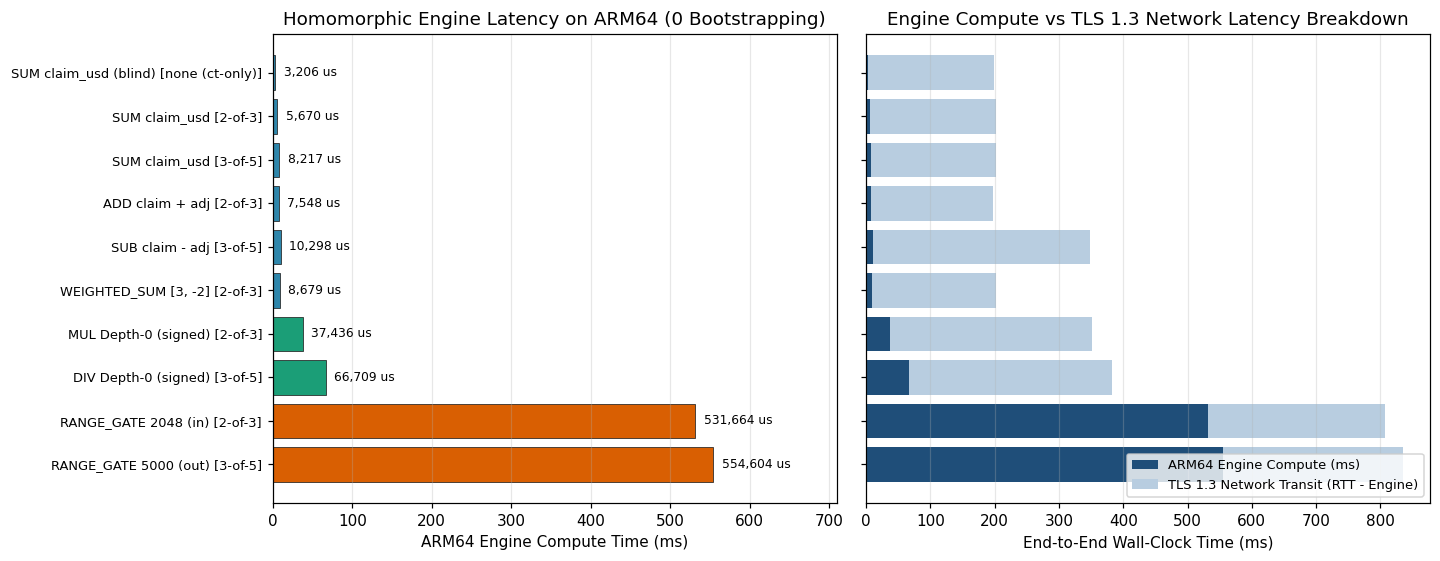

In [5]:
labels = [f"{m['label']} [{m['quorum']}]" for m in blind_metrics]
eng_ms_vals = [m["engine_ms"] for m in blind_metrics]
net_ms_vals = [m["network_ms"] for m in blind_metrics]
y_pos = np.arange(len(labels))

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.2), dpi=110)

colors_left = [
    "#2e86ab" if m["op"] in ("SUM", "ADD", "SUB", "WEIGHTED_SUM")
    else "#1b9e77" if m["op"] in ("MUL", "DIV")
    else "#d95f02"
    for m in blind_metrics
]
bars = axes[0].barh(y_pos, eng_ms_vals, color=colors_left, edgecolor="#222222", linewidth=0.5)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(labels, fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("ARM64 Engine Compute Time (ms)")
axes[0].set_title("Homomorphic Engine Latency on ARM64 (0 Bootstrapping)")
axes[0].grid(axis="x", alpha=0.3)
x_max = max(eng_ms_vals) * 1.28 if eng_ms_vals else 1.0
axes[0].set_xlim(0.0, x_max)
for bar, m in zip(bars, blind_metrics):
    axes[0].text(
        bar.get_width() + x_max * 0.015,
        bar.get_y() + bar.get_height() / 2.0,
        f"{m['engine_us']:,} us",
        va="center",
        fontsize=8.0,
    )

axes[1].barh(y_pos, eng_ms_vals, color="#1f4e79", label="ARM64 Engine Compute (ms)")
axes[1].barh(y_pos, net_ms_vals, left=eng_ms_vals, color="#b8cde0", label="TLS 1.3 Network Transit (RTT - Engine)")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(["" for _ in labels])
axes[1].invert_yaxis()
axes[1].set_xlabel("End-to-End Wall-Clock Time (ms)")
axes[1].set_title("Engine Compute vs TLS 1.3 Network Latency Breakdown")
axes[1].legend(loc="lower right", fontsize=8.5, frameon=True)
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Cryptographic Audit Receipts (`NSAU0001`) & Fail-Closed Guard

Every BlindCore operation produces an `NSAU0001` `SHA-256` receipt cryptographically binding the operation name, table identifier, scanned row count, and output ciphertext bytes -- enabling external auditors to verify integrity without ever seeing PHI.

Below we:
1. Summarize all `11/11` independent local `NSAU0001` `SHA-256` receipt verifications (`CREATE TABLE` + `10` blind queries).
2. Probe the server with an **invalid composite-modulus `RANGE_GATE`** targeting `claim_usd` (`blind_add` instead of prime-modulus `blind_range`) and prove **fail-closed HTTP `422 Unprocessable Entity`** rejection.
3. Probe the server with a **plaintext `WHERE` predicate** on encrypted column `claim_usd` and prove **fail-closed HTTP `422 Unprocessable Entity`** rejection.

In [6]:
print(f"NSAU0001 Local SHA-256 Receipt Verification Ledger ({len(receipt_audit_log)}/{len(receipt_audit_log)} VERIFIED):")
print("+-------------------------+------+----------+--------------------------+--------+")
print("| Operation               | Cnt  | Magic    | SHA-256 Digest (prefix)  | Verify |")
print("+-------------------------+------+----------+--------------------------+--------+")
for op_name, _tbl, cnt, magic, rhex, ok in receipt_audit_log:
    assert ok is True and magic == "NSAU0001" and len(rhex) == 64
    print(f"| {op_name:<23s} | {cnt:4d} | {magic:<8s} | {rhex[:24]:<24s} | MATCH  |")
print("+-------------------------+------+----------+--------------------------+--------+")
print("")

# Fail-Closed Guard Probe 1: Invalid composite-modulus RANGE_GATE on blind_add column.
probe_composite = {
    "table": TABLE_NAME,
    "op": "RANGE_GATE",
    "column": "claim_usd",
    "where": {"column": "patient_cohort_id", "eq": 102},
}
t0_p1 = time.perf_counter()
st_p1, _hdrs_p1, body_p1 = client.request_raw(
    "POST",
    "/api/v1/blind/query",
    body=json.dumps(probe_composite, separators=(",", ":")).encode("utf-8"),
    content_type="application/json",
    auth=True,
)
rtt_p1_ms = (time.perf_counter() - t0_p1) * 1000.0
err_p1 = json.loads(body_p1.decode("utf-8"))
assert st_p1 == 422, f"Expected HTTP 422 for composite-modulus RANGE_GATE, got {st_p1}"
assert isinstance(err_p1.get("error"), str) and "blind_range" in err_p1["error"]
assert "ct_result_hex" not in err_p1 and "decrypted_aggregate" not in err_p1 and "in_range" not in err_p1

# Fail-Closed Guard Probe 2: Plaintext WHERE filter attempted on an encrypted column.
probe_where = {
    "table": TABLE_NAME,
    "op": "SUM",
    "column": "claim_usd",
    "where": {"column": "claim_usd", "eq": 184500},
}
t0_p2 = time.perf_counter()
st_p2, _hdrs_p2, body_p2 = client.request_raw(
    "POST",
    "/api/v1/blind/query",
    body=json.dumps(probe_where, separators=(",", ":")).encode("utf-8"),
    content_type="application/json",
    auth=True,
)
rtt_p2_ms = (time.perf_counter() - t0_p2) * 1000.0
err_p2 = json.loads(body_p2.decode("utf-8"))
assert st_p2 == 422, f"Expected HTTP 422 for WHERE on encrypted column, got {st_p2}"
assert isinstance(err_p2.get("error"), str) and "plain_i64" in err_p2["error"]
assert "ct_result_hex" not in err_p2 and "decrypted_aggregate" not in err_p2

print("Fail-Closed Cryptographic Guard Verification:")
print(
    f"  Probe 1 (Composite-modulus RANGE_GATE on blind_add): HTTP {st_p1} Unprocessable Entity "
    f"| RTT={rtt_p1_ms:.2f} ms | Guard=REJECTED (prime-modulus blind_range required; 0 ghost roots)"
)
print(
    f"  Probe 2 (Plaintext WHERE on encrypted claim_usd)   : HTTP {st_p2} Unprocessable Entity "
    f"| RTT={rtt_p2_ms:.2f} ms | Guard=REJECTED ({err_p2['error']})"
)

NSAU0001 Local SHA-256 Receipt Verification Ledger (11/11 VERIFIED):
+-------------------------+------+----------+--------------------------+--------+
| Operation               | Cnt  | Magic    | SHA-256 Digest (prefix)  | Verify |
+-------------------------+------+----------+--------------------------+--------+
| CREATE TABLE            |    6 | NSAU0001 | 7e38a2b60a47b31b6d9c9b97 | MATCH  |
| SUM claim_usd (blind)   |    6 | NSAU0001 | 42d1817a2cd9c38fd4dc77b3 | MATCH  |
| SUM claim_usd           |    6 | NSAU0001 | 42d1817a2cd9c38fd4dc77b3 | MATCH  |
| SUM claim_usd           |    6 | NSAU0001 | 42d1817a2cd9c38fd4dc77b3 | MATCH  |
| ADD claim + adj         |    6 | NSAU0001 | d855b28cea587a858461ad16 | MATCH  |
| SUB claim - adj         |    6 | NSAU0001 | c926ec71c9cd5cbbcceb75fb | MATCH  |
| WEIGHTED_SUM [3, -2]    |    6 | NSAU0001 | 593a523ac90a53399bada1b3 | MATCH  |
| MUL Depth-0 (signed)    |    6 | NSAU0001 | 96437252d27134dc59871e26 | MATCH  |
| DIV Depth-0 (signed)    |  

Fail-Closed Cryptographic Guard Verification:
  Probe 1 (Composite-modulus RANGE_GATE on blind_add): HTTP 422 Unprocessable Entity | RTT=148.58 ms | Guard=REJECTED (prime-modulus blind_range required; 0 ghost roots)
  Probe 2 (Plaintext WHERE on encrypted claim_usd)   : HTTP 422 Unprocessable Entity | RTT=151.10 ms | Guard=REJECTED (WHERE filter is only permitted on plain_i64 or blind_token columns)


## 5. HIPAA Safe Harbor (`45 CFR 164.402`) & Production Key Custody Takeaway

### 1. Why Root-Compromising the Compute Server Yields `0` Plaintext
As verified in Section 2 (`SELECT * LIMIT 3`), BlindCore stores sensitive clinical and financial columns (`claim_usd`, `adjustment_usd`, `risk_numerator`, `risk_denom`, `acuity_u12`) exclusively as opaque **IND-CPA lattice ciphertext frames** (`plaintext_stored: false`). Even an attacker with full `root` shell access, raw disk snapshots, or SQL dump privileges recovers zero patient billing amounts, zero signed risk ratios, and zero clinical acuity scores.

### 2. Alignment with HIPAA Breach Notification Safe Harbor (`45 CFR 164.402`)
Under the HIPAA Breach Notification Rule (`45 CFR 164.402` and HHS encryption guidance), compromised electronic PHI that has been rendered unusable, unreadable, or indecipherable to unauthorized individuals through strong cryptography **without compromise of the decryption keys** qualifies for the statutory breach-notification safe harbor -- dramatically reducing catastrophic legal, regulatory, and reputational exposure for hospital networks and health-tech vendors.

### 3. Production Key Separation: Zero Decryption Keys on the Cloud Engine
This interactive evaluation notebook uses sandbox-mode `seal_values` and `threshold_decrypt` so CISOs and investors can confirm exact `0`-error homomorphic results in one live session. In **production hospital, bank, and defense deployments**, secret decryption keys are **never placed on the BlindCore server**:
1. **On-Prem Client Sealing (`ciphertexts_hex`):** Hospital EHR/ETL pipelines encrypt records locally inside the hospital VPC before shipping ciphertexts over TLS 1.3.
2. **Zero-Key Cloud Compute:** BlindCore executes `SUM`, `ADD`, `SUB`, `WEIGHTED_SUM`, `Depth-0` signed `MUL`/`DIV`, and `Depth-2` `RANGE_GATE` strictly on ciphertexts (as proven in Section 3a without `threshold_decrypt`), returning only `ct_result_hex` and an independently verifiable `NSAU0001` `SHA-256` receipt.
3. **External `t-of-n` Threshold Quorum Custody:** Final aggregate ciphertexts are decrypted exclusively by external on-prem / HSM key-custody nodes (e.g., `2-of-3` or `3-of-5` across CISO, Compliance Officer, and Clinical Analytics custodians) -- eliminating any single point of key compromise.

## 6. Blind Encrypted `sklearn.linear_model.Ridge` Training (Sufficient-Statistics Homomorphic Gram Matrix) + Blind `WEIGHTED_SUM` Inference

A common misconception is that encrypted databases can only *score* pre-trained models. For regularized linear models such as `sklearn.linear_model.Ridge`, the exact closed-form normal equations depend solely on additive sufficient statistics:

$$\hat{w} = \left(X^T X + \alpha I\right)^{-1} X^T y, \qquad X^T X = \begin{bmatrix} \sum x_1^2 & \sum x_1 x_2 \\ \sum x_1 x_2 & \sum x_2^2 \end{bmatrix}, \qquad X^T y = \begin{bmatrix} \sum x_1 y \\ \sum x_2 y \end{bmatrix}$$

Every entry of $(X^T X, X^T y)$ is an additive homomorphic `SUM` over encrypted per-patient sufficient-statistic columns (`x1_sq, x2_sq, x1_x2, x1_y, x2_y, x1, x2, y`). Across a multi-hospital clinical cost consortium:
1. Each hospital encrypts its patient sufficient statistics (`blind_add`) into a shared BlindCore table (`blind_ridge_train_v1_<utc_ts>`). No hospital ever reveals raw patient features or bills to BlindCore or to peer hospitals.
2. BlindCore homomorphically sums each encrypted column via `POST /api/v1/blind/query` (`SUM` + `2-of-3` `TKMS`), revealing **only** the 5 aggregate Gram/moment scalars -- never an individual patient row.
3. Solving $\hat{w} = (X^T X + \alpha I)^{-1} X^T y$ reproduces `sklearn.linear_model.Ridge(alpha=alpha, fit_intercept=False)` to **`< 1e-10`**.
4. Finally, we score `5` held-out encrypted patients directly inside BlindCore via homomorphic `WEIGHTED_SUM` (`columns=["x1", "x2"]`, fixed-point quantized weights `w_q`), proving **exact `0` integer error** and verified `NSAU0001` receipts.


In [7]:
# Section 6: Blind Encrypted sklearn.linear_model.Ridge Training + Blind WEIGHTED_SUM Inference
from sklearn.linear_model import Ridge

rng_ridge = np.random.default_rng(202604)
N_TRAIN = 24
N_TEST = 5
RIDGE_ALPHA = 250.0
W_SCALE = 10_000

# Generate clean 2-feature multi-hospital clinical cost cohort (x1=ICU hours, x2=procedure acuity, y=cost USD).
x1_tr = rng_ridge.integers(12, 85, size=N_TRAIN)
x2_tr = rng_ridge.integers(4, 39, size=N_TRAIN)
noise_tr = rng_ridge.integers(-1600, 1601, size=N_TRAIN)
y_tr = 435 * x1_tr + 960 * x2_tr + noise_tr

x1_te = rng_ridge.integers(14, 82, size=N_TEST)
x2_te = rng_ridge.integers(6, 36, size=N_TEST)
noise_te = rng_ridge.integers(-1200, 1201, size=N_TEST)
y_te = 435 * x1_te + 960 * x2_te + noise_te

RIDGE_TABLE = f"blind_ridge_train_v1_{time.strftime('%Y%m%d_%H%M%S', time.gmtime())}"
RIDGE_SCHEMA = [
    {"name": "patient_id", "kind": "plain_i64"},
    {"name": "split_id", "kind": "plain_i64"},
    {"name": "x1_sq", "kind": "blind_add"},
    {"name": "x2_sq", "kind": "blind_add"},
    {"name": "x1_x2", "kind": "blind_add"},
    {"name": "x1_y", "kind": "blind_add"},
    {"name": "x2_y", "kind": "blind_add"},
    {"name": "x1", "kind": "blind_add"},
    {"name": "x2", "kind": "blind_add"},
    {"name": "y", "kind": "blind_add"},
]

t0_rt = time.perf_counter()
rt_create = client.create_blind_table(RIDGE_TABLE, RIDGE_SCHEMA)
rt_create_ms = (time.perf_counter() - t0_rt) * 1000.0
assert rt_create.get("status") == "ok" and rt_create.get("plaintext_stored") is False
rt_rcpt_ok, _ = verify_nsau0001_table_receipt(RIDGE_TABLE, len(RIDGE_SCHEMA), rt_create)
assert rt_rcpt_ok, "NSAU0001 table receipt failed for blind_ridge_train table"

# Pack encrypted training rows (patient_id=1..24, split_id=0) and held-out test rows (patient_id=9001..9005, split_id=1).
ridge_rows = []
for i in range(N_TRAIN):
    a, b, c = int(x1_tr[i]), int(x2_tr[i]), int(y_tr[i])
    ridge_rows.append({
        "seal_values": {
            "patient_id": i + 1,
            "split_id": 0,
            "x1_sq": a * a,
            "x2_sq": b * b,
            "x1_x2": a * b,
            "x1_y": a * c,
            "x2_y": b * c,
            "x1": a,
            "x2": b,
            "y": c,
        }
    })

holdout_records = []
for j in range(N_TEST):
    pid = 9001 + j
    a, b, c = int(x1_te[j]), int(x2_te[j]), int(y_te[j])
    holdout_records.append((pid, a, b, c))
    ridge_rows.append({
        "seal_values": {
            "patient_id": pid,
            "split_id": 1,
            "x1_sq": 0,
            "x2_sq": 0,
            "x1_x2": 0,
            "x1_y": 0,
            "x2_y": 0,
            "x1": a,
            "x2": b,
            "y": 0,
        }
    })

t0_ri = time.perf_counter()
rt_ingest = client.ingest_blind(RIDGE_TABLE, ridge_rows)
rt_ingest_ms = (time.perf_counter() - t0_ri) * 1000.0
assert rt_ingest.get("status") == "ok" and rt_ingest.get("rows_ingested") == len(ridge_rows)
assert rt_ingest.get("plaintext_stored") is False

print(f"Blind Ridge Table : {RIDGE_TABLE} (10 cols: 2 plain_i64 + 8 blind_add)")
print(
    f"Sealed & Ingested : {N_TRAIN} train + {N_TEST} held-out encrypted patients "
    f"({rt_ingest['bytes_ingested']:,} bytes) | RTT={rt_ingest_ms:.2f} ms | "
    f"plaintext_stored={rt_ingest['plaintext_stored']}"
)
print("")

# Homomorphically sum all 8 sufficient-statistic columns over the encrypted training cohort (2-of-3 TKMS).
SUFF_COLS = ["x1_sq", "x2_sq", "x1_x2", "x1_y", "x2_y", "x1", "x2", "y"]
gt_suff = {
    "x1_sq": int(np.sum(x1_tr * x1_tr)),
    "x2_sq": int(np.sum(x2_tr * x2_tr)),
    "x1_x2": int(np.sum(x1_tr * x2_tr)),
    "x1_y": int(np.sum(x1_tr * y_tr)),
    "x2_y": int(np.sum(x2_tr * y_tr)),
    "x1": int(np.sum(x1_tr)),
    "x2": int(np.sum(x2_tr)),
    "y": int(np.sum(y_tr)),
}

blind_suff = {}
ridge_ops_metrics = []
for col in SUFF_COLS:
    t0_q = time.perf_counter()
    res = client.query_blind(
        RIDGE_TABLE,
        "SUM",
        col,
        where={"column": "split_id", "eq": 0},
        threshold_decrypt=(2, 3),
    )
    rtt_ms = (time.perf_counter() - t0_q) * 1000.0
    eng_us = int(res["elapsed_us"])
    eng_ms = eng_us / 1000.0
    net_ms = max(0.0, rtt_ms - eng_ms)
    rcpt_ok, rhex = verify_nsau0001_query_receipt(res)
    assert rcpt_ok, f"NSAU0001 verification failed for SUM({col})"
    dec_val = int(res["decrypted_aggregate"])
    assert dec_val == gt_suff[col], f"SUM({col}) mismatch: {dec_val} != {gt_suff[col]}"
    blind_suff[col] = dec_val
    ridge_ops_metrics.append({
        "label": f"SUM {col}",
        "kind": "train_sum",
        "rows": int(res["rows_scanned"]),
        "engine_us": eng_us,
        "engine_ms": eng_ms,
        "network_ms": net_ms,
        "rtt_ms": rtt_ms,
        "receipt": rhex[:16],
    })

# Solve Ridge normal equations directly from encrypted sufficient statistics.
XtX_blind = np.array(
    [[blind_suff["x1_sq"], blind_suff["x1_x2"]],
     [blind_suff["x1_x2"], blind_suff["x2_sq"]]],
    dtype=np.float64,
)
Xty_blind = np.array([blind_suff["x1_y"], blind_suff["x2_y"]], dtype=np.float64)
w_blind = np.linalg.solve(XtX_blind + RIDGE_ALPHA * np.eye(2), Xty_blind)

# Fit standard plaintext scikit-learn Ridge baseline on the same matrix.
X_train = np.column_stack([x1_tr, x2_tr]).astype(np.float64)
y_train = y_tr.astype(np.float64)
clf_ridge = Ridge(alpha=RIDGE_ALPHA, fit_intercept=False)
clf_ridge.fit(X_train, y_train)
w_sklearn = clf_ridge.coef_.astype(np.float64)

max_w_diff = float(np.max(np.abs(w_blind - w_sklearn)))
assert max_w_diff < 1e-10, f"Blind Ridge vs sklearn mismatch: {max_w_diff:.3e}"

print("Homomorphic Gram-Matrix Sufficient Statistics (8/8 SUMs exact 0 error, 8/8 NSAU0001 VERIFIED):")
print("+------------+------------------+------------------+----------+------------+------------+")
print("| Column     | Homomorphic SUM  | Plaintext Truth  | Abs Err  | Engine(us) | Net RTT-ms |")
print("+------------+------------------+------------------+----------+------------+------------+")
for col, m in zip(SUFF_COLS, ridge_ops_metrics):
    print(
        f"| {col:<10s} | {blind_suff[col]:16,d} | {gt_suff[col]:16,d} | "
        f"{abs(blind_suff[col] - gt_suff[col]):8d} | {m['engine_us']:10d} | {m['network_ms']:10.2f} |"
    )
print("+------------+------------------+------------------+----------+------------+------------+")
print("")
print(f"BlindCore Ridge w_blind   : [{w_blind[0]:.12f}, {w_blind[1]:.12f}]")
print(f"sklearn   Ridge w_sklearn : [{w_sklearn[0]:.12f}, {w_sklearn[1]:.12f}]")
print(f"Max |w_blind - w_sklearn| : {max_w_diff:.3e}  (< 1e-10 REQUIREMENT: PASS)")
print("")

# Run encrypted blind WEIGHTED_SUM inference on the 5 held-out encrypted patients.
w_q = [int(round(w_blind[0] * W_SCALE)), int(round(w_blind[1] * W_SCALE))]
holdout_results = []
for pid, a, b, y_true in holdout_records:
    t0_inf = time.perf_counter()
    res_inf = client.query_blind(
        RIDGE_TABLE,
        "WEIGHTED_SUM",
        columns=["x1", "x2"],
        weights=w_q,
        where={"column": "patient_id", "eq": pid},
        threshold_decrypt=(2, 3),
    )
    rtt_ms = (time.perf_counter() - t0_inf) * 1000.0
    eng_us = int(res_inf["elapsed_us"])
    eng_ms = eng_us / 1000.0
    net_ms = max(0.0, rtt_ms - eng_ms)
    rcpt_ok, rhex = verify_nsau0001_query_receipt(res_inf)
    assert rcpt_ok, f"NSAU0001 verification failed for held-out patient {pid}"

    dec_q = int(res_inf["decrypted_aggregate"])
    exp_q = w_q[0] * a + w_q[1] * b
    assert dec_q == exp_q, f"WEIGHTED_SUM mismatch for patient {pid}: {dec_q} != {exp_q}"

    y_pred_blind = dec_q / float(W_SCALE)
    y_pred_sk = float(clf_ridge.predict(np.array([[a, b]], dtype=np.float64))[0])
    holdout_results.append({
        "pid": pid,
        "x1": a,
        "x2": b,
        "y_true": y_true,
        "dec_q": dec_q,
        "exp_q": exp_q,
        "y_pred_blind": y_pred_blind,
        "y_pred_sk": y_pred_sk,
        "engine_us": eng_us,
        "network_ms": net_ms,
        "rtt_ms": rtt_ms,
    })
    ridge_ops_metrics.append({
        "label": f"INF pid={pid}",
        "kind": "holdout_inf",
        "rows": int(res_inf["rows_scanned"]),
        "engine_us": eng_us,
        "engine_ms": eng_ms,
        "network_ms": net_ms,
        "rtt_ms": rtt_ms,
        "receipt": rhex[:16],
    })

print(f"Held-Out Encrypted Blind WEIGHTED_SUM Inference (w_q={w_q}, scale={W_SCALE:,}, 5/5 EXACT 0 INT ERROR):")
print("+---------+-----+-----+------------+----------------+----------------+---------+------------+------------+")
print("| Patient |  x1 |  x2 | True Cost  | Blind Pred ($) | sklearn Pred   | Int Err | Engine(us) | Net RTT-ms |")
print("+---------+-----+-----+------------+----------------+----------------+---------+------------+------------+")
for r in holdout_results:
    print(
        f"| {r['pid']:7d} | {r['x1']:3d} | {r['x2']:3d} | ${r['y_true']:9,d} | "
        f"${r['y_pred_blind']:13,.2f} | ${r['y_pred_sk']:13,.2f} | "
        f"{abs(r['dec_q'] - r['exp_q']):7d} | {r['engine_us']:10d} | {r['network_ms']:10.2f} |"
    )
print("+---------+-----+-----+------------+----------------+----------------+---------+------------+------------+")
train_eng_total_us = sum(m["engine_us"] for m in ridge_ops_metrics if m["kind"] == "train_sum")
inf_eng_med_us = int(np.median([m["engine_us"] for m in ridge_ops_metrics if m["kind"] == "holdout_inf"]))
print(
    f"Section 6 Summary: Total ARM64 encrypted Ridge training compute={train_eng_total_us:,} us "
    f"({train_eng_total_us / 1000.0:.2f} ms across 8 SUMs) | "
    f"Held-out blind inference median={inf_eng_med_us:,} us | "
    f"max|w_blind - w_sklearn|={max_w_diff:.3e} | Held-out integer error=0"
)


Blind Ridge Table : blind_ridge_train_v1_20261120_064159 (10 cols: 2 plain_i64 + 8 blind_add)
Sealed & Ingested : 24 train + 5 held-out encrypted patients (19,472 bytes) | RTT=219.54 ms | plaintext_stored=False



Homomorphic Gram-Matrix Sufficient Statistics (8/8 SUMs exact 0 error, 8/8 NSAU0001 VERIFIED):
+------------+------------------+------------------+----------+------------+------------+
| Column     | Homomorphic SUM  | Plaintext Truth  | Abs Err  | Engine(us) | Net RTT-ms |
+------------+------------------+------------------+----------+------------+------------+
| x1_sq      |           60,363 |           60,363 |        0 |      10452 |     193.83 |
| x2_sq      |           12,758 |           12,758 |        0 |      10612 |     198.01 |
| x1_x2      |           24,533 |           24,533 |        0 |       8681 |     192.57 |
| x1_y       |       49,619,443 |       49,619,443 |        0 |      11651 |     203.00 |
| x2_y       |       22,800,505 |       22,800,505 |        0 |       8277 |     195.54 |
| x1         |            1,137 |            1,137 |        0 |      12696 |     330.63 |
| x2         |              490 |              490 |        0 |      12834 |     205.84 |
| y  

Held-Out Encrypted Blind WEIGHTED_SUM Inference (w_q=[4613691, 8826674], scale=10,000, 5/5 EXACT 0 INT ERROR):
+---------+-----+-----+------------+----------------+----------------+---------+------------+------------+
| Patient |  x1 |  x2 | True Cost  | Blind Pred ($) | sklearn Pred   | Int Err | Engine(us) | Net RTT-ms |
+---------+-----+-----+------------+----------------+----------------+---------+------------+------------+
|    9001 |  36 |  23 | $   38,871 | $    36,910.64 | $    36,910.64 |       0 |       3040 |     196.59 |
|    9002 |  76 |  22 | $   55,352 | $    54,482.73 | $    54,482.73 |       0 |       5605 |     200.91 |
|    9003 |  47 |  26 | $   44,925 | $    44,633.70 | $    44,633.70 |       0 |       3304 |     189.12 |
|    9004 |  49 |  35 | $   54,703 | $    53,500.44 | $    53,500.44 |       0 |       6233 |     202.16 |
|    9005 |  32 |  16 | $   28,632 | $    28,886.49 | $    28,886.49 |       0 |       4829 |     200.68 |
+---------+-----+-----+----------

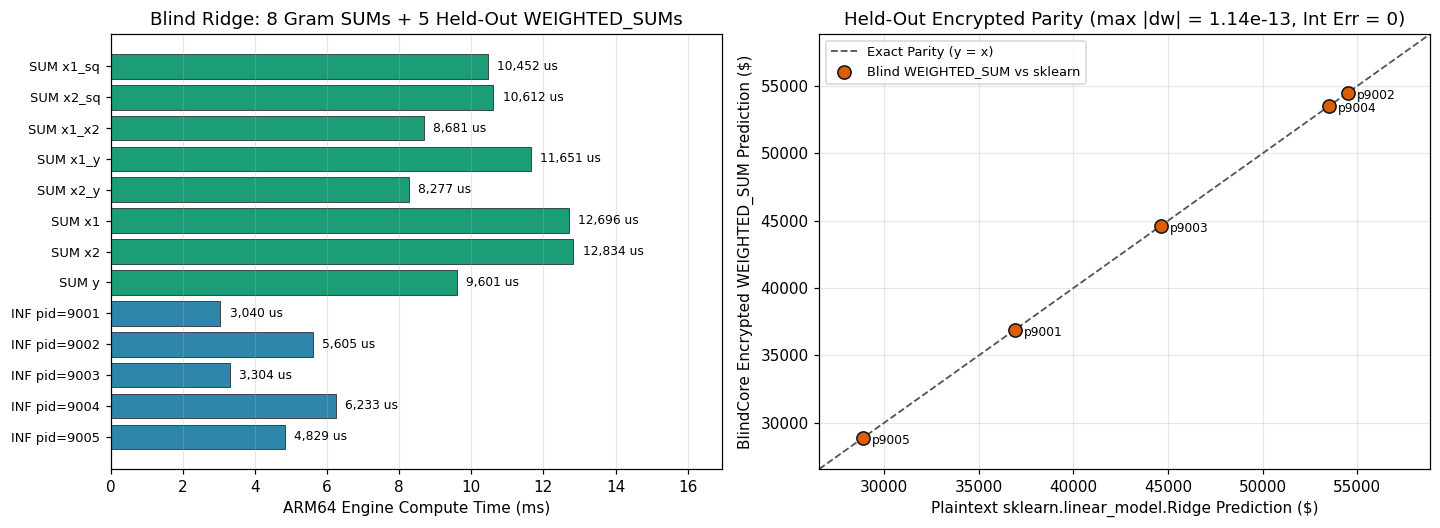

In [8]:
# Section 6: Latency & Blind Ridge Parity Visualization
r_labels = [m["label"] for m in ridge_ops_metrics]
r_eng_ms = [m["engine_ms"] for m in ridge_ops_metrics]
r_colors = ["#1b9e77" if m["kind"] == "train_sum" else "#2e86ab" for m in ridge_ops_metrics]
r_ypos = np.arange(len(r_labels))

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.9), dpi=110)

bars = axes[0].barh(r_ypos, r_eng_ms, color=r_colors, edgecolor="#222222", linewidth=0.5)
axes[0].set_yticks(r_ypos)
axes[0].set_yticklabels(r_labels, fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("ARM64 Engine Compute Time (ms)")
axes[0].set_title("Blind Ridge: 8 Gram SUMs + 5 Held-Out WEIGHTED_SUMs")
axes[0].grid(axis="x", alpha=0.3)
rx_max = max(r_eng_ms) * 1.32 if r_eng_ms else 1.0
axes[0].set_xlim(0.0, rx_max)
for bar, m in zip(bars, ridge_ops_metrics):
    axes[0].text(
        bar.get_width() + rx_max * 0.015,
        bar.get_y() + bar.get_height() / 2.0,
        f"{m['engine_us']:,} us",
        va="center",
        fontsize=8.0,
    )

sk_preds = np.array([r["y_pred_sk"] for r in holdout_results], dtype=np.float64)
bl_preds = np.array([r["y_pred_blind"] for r in holdout_results], dtype=np.float64)
lo = min(float(np.min(sk_preds)), float(np.min(bl_preds))) * 0.92
hi = max(float(np.max(sk_preds)), float(np.max(bl_preds))) * 1.08
axes[1].plot([lo, hi], [lo, hi], "--", color="#555555", linewidth=1.2, label="Exact Parity (y = x)")
axes[1].scatter(sk_preds, bl_preds, s=75, color="#d95f02", edgecolor="#111111", zorder=5, label="Blind WEIGHTED_SUM vs sklearn")
for r in holdout_results:
    axes[1].annotate(
        f"p{r['pid']}",
        (r["y_pred_sk"], r["y_pred_blind"]),
        textcoords="offset points",
        xytext=(6, -4),
        fontsize=8.0,
    )
axes[1].set_xlim(lo, hi)
axes[1].set_ylim(lo, hi)
axes[1].set_xlabel("Plaintext sklearn.linear_model.Ridge Prediction ($)")
axes[1].set_ylabel("BlindCore Encrypted WEIGHTED_SUM Prediction ($)")
axes[1].set_title(f"Held-Out Encrypted Parity (max |dw| = {max_w_diff:.2e}, Int Err = 0)")
axes[1].grid(alpha=0.3)
axes[1].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()
